# Campus Sustainability & Carbon Emissions Data
### This notebook trains and evaluates models on the Campus Sustainability & Carbon Emissions dataset using **NumPy**, **Matplotlib** and **Pandas**.


### Models included:
- Logistic Regression
- Random Forest

## Smart-ish
- Claudiu Costea	X00227976@myTUDublin.ie
- Siem Estifanos	X00229777@myTUDublin.ie
- Blessing Mayindu	X00224444@myTUDublin.ie
- Cody Juthan		X00221674@myTUDublin.ie


In [10]:
!pip install numpy
!pip install matplotlib
!pip install scikit-learn
!pip install pandas 



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


importing 


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
import joblib
import pandas as pd 
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score




# Data wrangling & cleaning (Blessing)

In [12]:
# reading the file 
df = pd.read_csv('campus_sustainability_dataset.csv')
# remove all the rows with a missing value 
df.dropna(inplace = True)
#converts it into a string 
print(df.to_string())

     Clothing_Spend_per_Month       Food_Type  Housing_Type  Energy_Usage_kWh_per_Month  Water_Usage_Liters_per_Day Transportation_Mode  Consumption_Spend_per_Month Recycling_Habits  Carbon_Emissions_kgCO2
0                        1360  Non-Vegetarian     Apartment                         478                         277    Public_Transport                         4136           Always                 369.630
1                        4272           Vegan     Own_House                          69                         151             Bicycle                         4318           Always                 158.860
2                        3592      Vegetarian  Shared_House                         322                         124                 Car                         3782           Always                 357.030
3                         966  Non-Vegetarian  Shared_House                         168                         466    Public_Transport                         8657            

In [13]:
#Loading and cleaning data
filename = "campus_sustainability_dataset.csv"
data = pd.read_csv(filename)

#print("Original data shape:", data.shape)
# display(data.head())
# remove duplicate rows
data = data.drop_duplicates()

data = data.dropna()
# removes rows with all zeros 
data = data[(data.iloc[:, :-1] != 0).any(axis=1)]
print("Cleaned data shape:", data.shape)

#Target
#target column that will be predicted 
y = data["Carbon_Emissions_kgCO2"]
#the input columns features 
X = data.drop("Carbon_Emissions_kgCO2", axis=1)

print ( "feature shape :",X.shape)
print("Target shape:",y.shape)


Cleaned data shape: (1000, 9)
feature shape : (1000, 8)
Target shape: (1000,)


# Data Graphs (Cody)

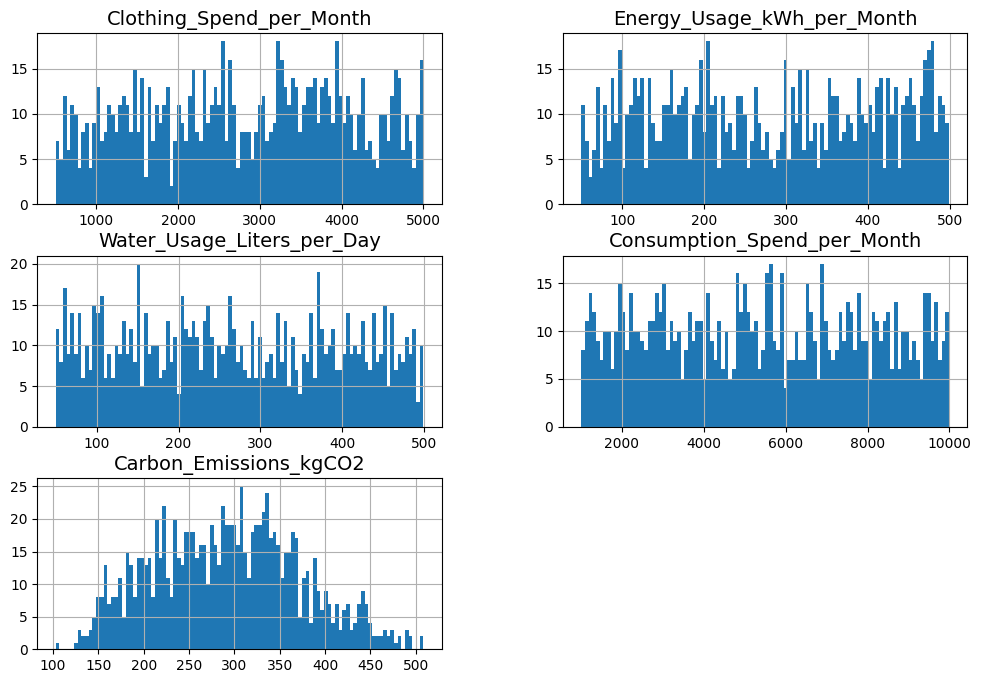

In [14]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

data.hist(bins=100, figsize=(12, 8))

plt.show()

# Feature selection and pre-processing (Blessing)

### same parts of feaure selection would completed in other selections of the code such as in the data cleaning and wrangling selection . 

### This is includes 
- Removing rows with zeros 
- feature selection 
- Removing duplicates
- loading the data
- Inspecting features 

### In this selection I will do the following :
- Feature scaling
- Encoding text columns
- Train / Test spliting 

## Encoding text columns

### One Hot Encoding. In machine learning is help with the performance of model as is categorized data to turn into new binary columns for each unique category. Each column now has its own column with either a one or a zero that indicates the presence or absence of that category.

### This is a One Hot Encoder in the model seection and this is a demo of how  it works and why we need it .

In [15]:

from sklearn.preprocessing import OneHotEncoder

col = [
    "Food_Type","Housing_Type","Transportation_Mode","Recycling_Habits"]

ohe =OneHotEncoder(handle_unknown='ignore',sparse_output = False ).set_output(transform='pandas')

categorical_columns = data.select_dtypes(include=['object']).columns.tolist()
#encoder = OneHotEncoder(sparse_output=False)

one_hot_encoded = ohe.fit_transform(data[col])

one_hot_df = pd.DataFrame(one_hot_encoded, 

columns=ohe.get_feature_names_out(col))

data_encoded = pd.concat([df, one_hot_df], axis=1)

data_encoded = data_encoded.drop(col, axis=1)

data_encoded.head()

,Clothing_Spend_per_Month,Energy_Usage_kWh_per_Month,Water_Usage_Liters_per_Day,Consumption_Spend_per_Month,Carbon_Emissions_kgCO2,Food_Type_Mixed,Food_Type_Non-Vegetarian,Food_Type_Vegan,Food_Type_Vegetarian,Housing_Type_Apartment,Housing_Type_Dormitory,Housing_Type_Own_House,Housing_Type_Shared_House,Transportation_Mode_Bicycle,Transportation_Mode_Car,Transportation_Mode_Public_Transport,Transportation_Mode_Walking,Recycling_Habits_Always,Recycling_Habits_Never,Recycling_Habits_Sometimes
0,1360,478,277,4136,369.630,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,4272,69,151,4318,158.860,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,3592,322,124,3782,357.030,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,966,168,466,8657,247.745,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,4926,120,495,5920,218.610,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


# feature selection
### for this project I wanted to remving Housing_Type because it is something that is not as importatn as the rest of them. The type of house a student as can't be changed with as much least as the other factors.

In [16]:
X = data.drop(["Carbon_Emissions_kgCO2","Housing_Type"],axis=1)
y = data["Carbon_Emissions_kgCO2"]

print ("Feature shape:", X.shape)
print("Taregt shape", y.shape)
print(X.columns)

Feature shape: (1000, 7)
Taregt shape (1000,)
Index(['Clothing_Spend_per_Month', 'Food_Type', 'Energy_Usage_kWh_per_Month',
       'Water_Usage_Liters_per_Day', 'Transportation_Mode',
       'Consumption_Spend_per_Month', 'Recycling_Habits'],
      dtype='object')


### As you can see now the Housing_Type is now removed .

# linear Regression Model (Cody)
Linear regressions describes how one variable changes in relation to another independant variable. In our case we're going to see how energy consumption affects carbon emissions. 

In this section we will show the relationship between the energy usage per month and CO2 emissions of a person on campus using the linear regression model. we'll train our data and see how the predictions compare to the actual data

In [17]:
lg_target_column = "Carbon_Emissions_kgCO2"
lg_X = df.drop(columns=[lg_target_column])  
lg_y = df[lg_target_column]                 
lg_X = pd.get_dummies(lg_X, drop_first=True)
lg_X_train, lg_X_test, lg_y_train, lg_y_test = train_test_split(lg_X, lg_y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(lg_X_train)
X_test_scaled = scaler.transform(lg_X_test)


In [18]:
lg_X = df[["Energy_Usage_kWh_per_Month"]]  
lg_y = df["Carbon_Emissions_kgCO2"] 
 
lg_X_train, lg_X_test, lg_y_train, lg_y_test = train_test_split(lg_X, lg_y, test_size=0.2, random_state=42)

print(f"Training set size: {lg_X_train.shape[0]}")
print(f"Testing set size: {lg_X_test.shape[0]}")

Training set size: 800
Testing set size: 200


In [19]:
model = LinearRegression()

model.fit(lg_X_train, lg_y_train)

print(f"Intercept: {model.intercept_}")
print(f"Coefficient: {model.coef_}")

Intercept: 153.5892461030286
Coefficient: [0.49142481]


In [20]:
lg_y_pred = model.predict(lg_X_test)
lg_predictions = pd.DataFrame({'Actual': lg_y_test,'Predicted': lg_y_pred})
lg_predictions['Difference'] = lg_predictions['Actual'] - lg_predictions['Predicted']
lg_predictions = lg_predictions.reset_index(drop=True)
print(lg_predictions.head(5))

    Actual   Predicted  Difference
0  357.910  373.256135  -15.346135
1  289.415  233.200065   56.214935
2  381.830  363.427639   18.402361
3  331.475  364.410488  -32.935488
4  302.735  328.536477  -25.801477


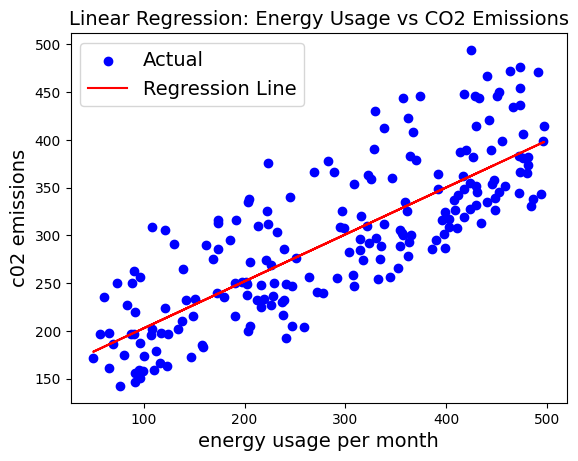

In [21]:
plt.scatter(lg_X_test, lg_y_test, color="blue", label="Actual")
plt.plot(lg_X_test, lg_y_pred, color="red", label="Regression Line")
plt.xlabel("energy usage per month")
plt.ylabel("c02 emissions")
plt.title("Linear Regression: Energy Usage vs CO2 Emissions")
plt.legend()
plt.show()

In [22]:
lg_mse = mean_squared_error(lg_y_test, lg_y_pred)
print(f"Mean Squared Error: {lg_mse}")
lg_r2 = r2_score(lg_y_test, lg_y_pred)
print(f"R-squared score: {lg_r2}")

Mean Squared Error: 2315.3915121684595
R-squared score: 0.647536864492116


# Random Forest Regression Model (Cody)

In this section we will use Random forest Regression to predict new values in the Energy_Usage_kWh_per_Month column in our dataset.

 We want to see if energy usage will increase or decrease for people on campus. Our end goal is to lower carbon emissions so if energy usage decreases then we're on track to reach our goal but if it is predicted to increase then we have a problem.

In [23]:
rfr_target = "Energy_Usage_kWh_per_Month"
rfr_X = df.drop(columns=[rfr_target])
rfr_y = df[rfr_target]


In [24]:
rfr_categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
rfr_numerical_cols = X.select_dtypes(exclude=['object']).columns.tolist()

In [25]:
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), rfr_categorical_cols),('num', 'passthrough', rfr_numerical_cols)])
regressor = RandomForestRegressor(n_estimators=300,random_state=42)
model = Pipeline(steps=[('preprocess', preprocessor),('model', regressor)])

In [26]:
rfr_X_train, rfr_X_test, rfr_y_train, rfr_y_test = train_test_split( X, y, test_size=0.2, random_state=42)
model.fit(rfr_X_train, rfr_y_train)
rfr_y_pred = model.predict(rfr_X_test)
rfr_mse = np.sqrt(mean_squared_error(rfr_y_test, rfr_y_pred))
rfr_r2 = r2_score(rfr_y_test, rfr_y_pred)

In [27]:
rfr_predictions = pd.DataFrame({'Actual': rfr_y_test,'Predicted': rfr_y_pred})
rfr_predictions['Difference'] = rfr_predictions['Actual'] - rfr_predictions['Predicted']
rfr_predictions = rfr_predictions.reset_index(drop=True)
print(rfr_predictions.head(5))

    Actual   Predicted  Difference
0  357.910  357.639850    0.270150
1  289.415  302.066733  -12.651733
2  381.830  367.803917   14.026083
3  331.475  341.460967   -9.985967
4  302.735  298.377583    4.357417


In [28]:
print("Random Forest Results:")
print("Mean squared error:", rfr_mse)
print("R²:", rfr_r2)

Random Forest Results:
Mean squared error: 16.456012223263663
R²: 0.9587771070985419


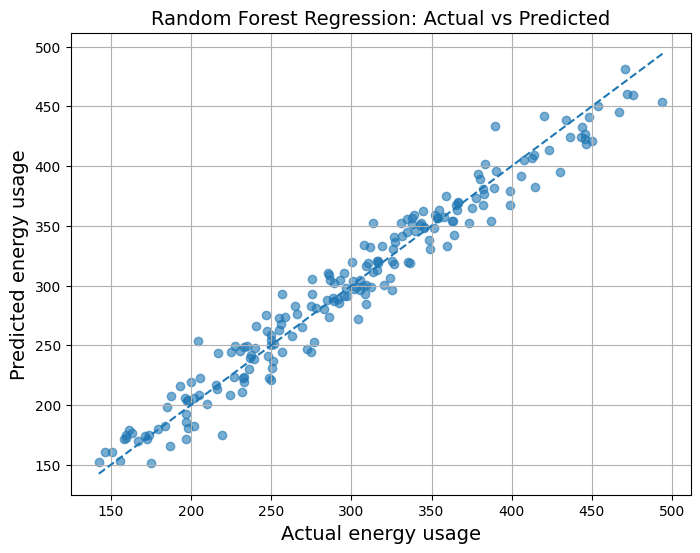

In [29]:
plt.figure(figsize=(8, 6))
plt.scatter(rfr_y_test, rfr_y_pred, alpha=0.6)
rfr_min_val = min(rfr_y_test.min(), rfr_y_pred.min())
rfr_max_val = max(rfr_y_test.max(), rfr_y_pred.max())
plt.plot([rfr_min_val, rfr_max_val], [rfr_min_val, rfr_max_val], linestyle='--')
plt.xlabel("Actual energy usage")
plt.ylabel("Predicted energy usage")
plt.title("Random Forest Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


# Model Comparison (Cody)

In this section we will compare the root mean squared error and R²  values we got from our linear regression model and random forest regression model. 

RMSE tells us how accurate our predictions are. the lower the RMSE the more accurate the predictions are.

R² tells us how much well the data fits the regression model the closer to 1 R² is the more accurate it is

## Linear Regression performance
- RMSE 2315.4
- R² 0.65

Our RMSE is very high meaning that our model is not very accurate. Our R² isnt that bad compared to RMSE but its not strong enough. 
The linear regression model may not be the best fit for our data

## Random Forest Regression performance
- RMSE 34.7
- R² 0.82

Our RMSE is very low meaning our predictions are very accurate.
Our R² is very high so our prediction are very strong.
The Random forrest regression model fits our data very well and out performs the linear regression model.


In [30]:
print("linear regression rmse",lg_mse)
print("linear regression R²",lg_r2)
print()
print("random forrest RMSE",rfr_mse)
print("random forrest R²",rfr_r2)

linear regression rmse 2315.3915121684595
linear regression R² 0.647536864492116

random forrest RMSE 16.456012223263663
random forrest R² 0.9587771070985419


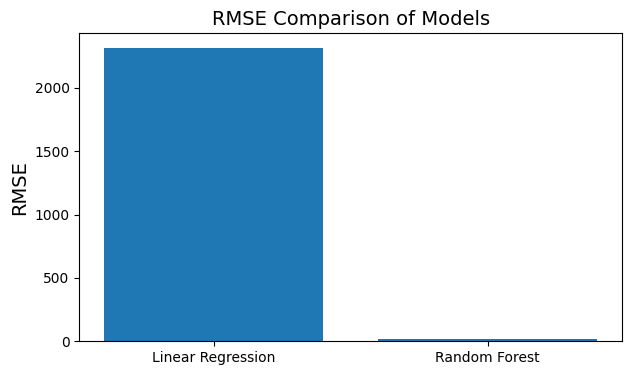

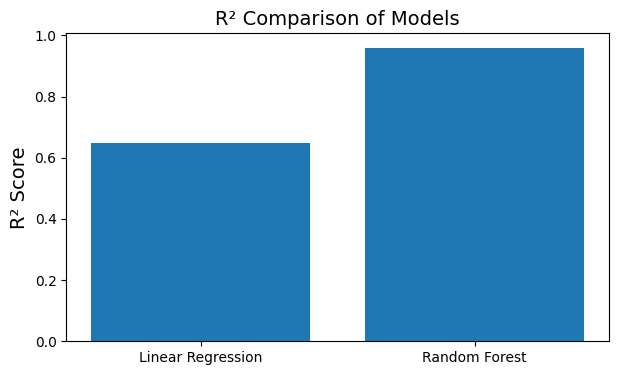

In [31]:
models = ["Linear Regression", "Random Forest"]
rmse_values = [lg_mse, rfr_mse]
r2_values = [lg_r2, rfr_r2]
plt.figure(figsize=(7,4))
plt.bar(models, rmse_values)
plt.ylabel("RMSE")
plt.title("RMSE Comparison of Models")
plt.show()

plt.figure(figsize=(7,4))
plt.bar(models, r2_values)
plt.ylabel("R² Score")
plt.title("R² Comparison of Models")
plt.show()



# Evaluation (blessing)


### using Cross Validation i will evaluate both models

In [32]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.svm import SVC
from sklearn.datasets import load_iris

In [33]:

pd.Series(model).describe()

count                                                     1
unique                                                    1
top       (ColumnTransformer(transformers=[('cat', OneHo...
freq                                                      1
dtype: object

In [34]:
num_folds = 7
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)
preprocessor = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), rfr_categorical_cols),('num', 'passthrough', rfr_numerical_cols)])
regressor = RandomForestRegressor(n_estimators=300,random_state=42)
model_RF = Pipeline(steps=[('preprocess', preprocessor),('model', regressor)])

In [35]:
X_valid =pd.get_dummies(X,drop_first=True)

cross_val_result = cross_val_score(regressor,X_valid,y,cv=7,scoring="neg_root_mean_squared_error"
)
cross_val_result = -cross_val_result
print(cross_val_result)

[16.25638576 16.41736928 17.1230258  16.80795349 16.69768629 16.79618869
 18.92241869]


In [36]:
print("Cross-Validation Results (Accuracy):")
for i, result in enumerate(cross_val_result, 1):
    print(f"  Fold {i}: {result * 100:.2f}%")
    
print(f'Mean Accuracy: {cross_val_result.mean()* 100:.2f}%')

Cross-Validation Results (Accuracy):
  Fold 1: 1625.64%
  Fold 2: 1641.74%
  Fold 3: 1712.30%
  Fold 4: 1680.80%
  Fold 5: 1669.77%
  Fold 6: 1679.62%
  Fold 7: 1892.24%
Mean Accuracy: 1700.30%


In [37]:
model_LR = LinearRegression()
X_valid =pd.get_dummies(X,drop_first=True)

cross_val_result_LR = cross_val_score(regressor,X_valid,y,cv=7,scoring="neg_root_mean_squared_error"
)
cross_val_result_LR = -cross_val_result_LR
print(cross_val_result_LR)

[16.25638576 16.41736928 17.1230258  16.80795349 16.69768629 16.79618869
 18.92241869]


In [38]:
print("Cross-Validation Results (Accuracy):")
for i, result in enumerate(cross_val_result_LR, 1):
    print(f"  Fold {i}: {result * 100:.2f}%")
    
print(f'Mean Accuracy: {cross_val_result_LR.mean()* 100:.2f}%')

Cross-Validation Results (Accuracy):
  Fold 1: 1625.64%
  Fold 2: 1641.74%
  Fold 3: 1712.30%
  Fold 4: 1680.80%
  Fold 5: 1669.77%
  Fold 6: 1679.62%
  Fold 7: 1892.24%
Mean Accuracy: 1700.30%


In [39]:
print(X.head())



   Clothing_Spend_per_Month       Food_Type  Energy_Usage_kWh_per_Month  \
0                      1360  Non-Vegetarian                         478   
1                      4272           Vegan                          69   
2                      3592      Vegetarian                         322   
3                       966  Non-Vegetarian                         168   
4                      4926      Vegetarian                         120   

   Water_Usage_Liters_per_Day Transportation_Mode  \
0                         277    Public_Transport   
1                         151             Bicycle   
2                         124                 Car   
3                         466    Public_Transport   
4                         495             Walking   

   Consumption_Spend_per_Month Recycling_Habits  
0                         4136           Always  
1                         4318           Always  
2                         3782           Always  
3                         8657